In [1]:
# QUESTION 2 A #
# Import required libraries

import numpy as np
import matplotlib.pyplot as plt

from sklearn.datasets import load_iris

from sklearn.cluster import KMeans
from sklearn.cluster import AgglomerativeClustering

from scipy.cluster.hierarchy import dendrogram
from scipy.cluster.hierarchy import linkage

from sklearn.metrics.pairwise import cosine_similarity

from scipy.spatial.distance import euclidean
from scipy.spatial.distance import cityblock

In [2]:
# Load iris dataset

iris = load_iris()

X = iris.data
y = iris.target

print("Dataset Shape :", X.shape)

Dataset Shape : (150, 4)


In [3]:
# Calculate Euclidean Distance

point1 = X[0]
point2 = X[1]

distance = euclidean(point1, point2)

print("Euclidean Distance")
print(distance)

Euclidean Distance
0.5385164807134502


In [4]:
# Calculate Manhattan Distance

distance = cityblock(point1, point2)

print("Manhattan Distance")
print(distance)

Manhattan Distance
0.6999999999999993


In [5]:
# Calculate Cosine Similarity

similarity = cosine_similarity(
    point1.reshape(1,-1),
    point2.reshape(1,-1)
)

print("Cosine Similarity")
print(similarity)

Cosine Similarity
[[0.99857916]]


In [6]:
# Create KMeans model

kmeans = KMeans(
    n_clusters=3,
    random_state=42
)

clusters = kmeans.fit_predict(X)

print("Cluster Labels")

print(clusters)

Cluster Labels
[1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1
 1 1 1 1 1 1 1 1 1 1 1 1 1 0 2 0 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2
 2 2 2 0 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 0 2 0 0 0 0 2 0 0 0 0
 0 0 2 2 0 0 0 0 2 0 2 0 2 0 0 2 2 0 0 0 0 0 2 0 0 0 0 2 0 0 0 2 0 0 0 2 0
 0 2]


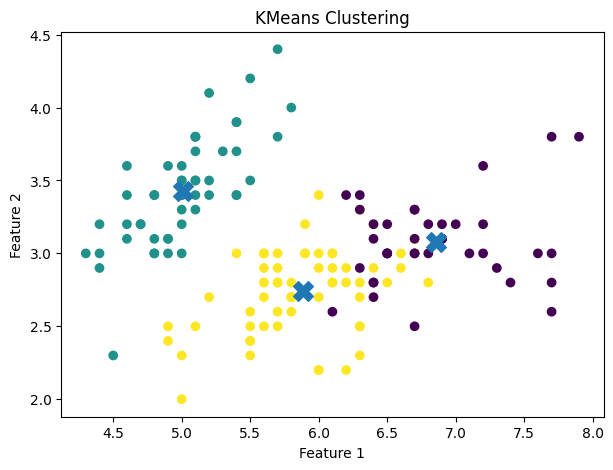

In [7]:
# Plot KMeans Clusters

plt.figure(figsize=(7,5))

plt.scatter(
    X[:,0],
    X[:,1],
    c=clusters
)

plt.scatter(
    kmeans.cluster_centers_[:,0],
    kmeans.cluster_centers_[:,1],
    marker="X",
    s=200
)

plt.title("KMeans Clustering")

plt.xlabel("Feature 1")

plt.ylabel("Feature 2")

plt.show()

In [8]:
# Create Hierarchical Clustering model

hierarchical = AgglomerativeClustering(
    n_clusters=3
)

hier_clusters = hierarchical.fit_predict(X)

print(hier_clusters)

[1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1
 1 1 1 1 1 1 1 1 1 1 1 1 1 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0 0 2 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 2 0 2 2 2 2 0 2 2 2 2
 2 2 0 0 2 2 2 2 0 2 0 2 0 2 2 0 0 2 2 2 2 2 0 0 2 2 2 0 2 2 2 0 2 2 2 0 2
 2 0]


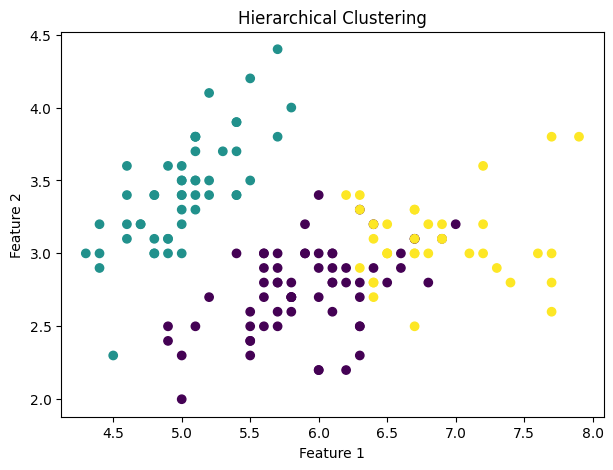

In [9]:
# Plot Hierarchical Clusters

plt.figure(figsize=(7,5))

plt.scatter(
    X[:,0],
    X[:,1],
    c=hier_clusters
)

plt.title("Hierarchical Clustering")

plt.xlabel("Feature 1")

plt.ylabel("Feature 2")

plt.show()

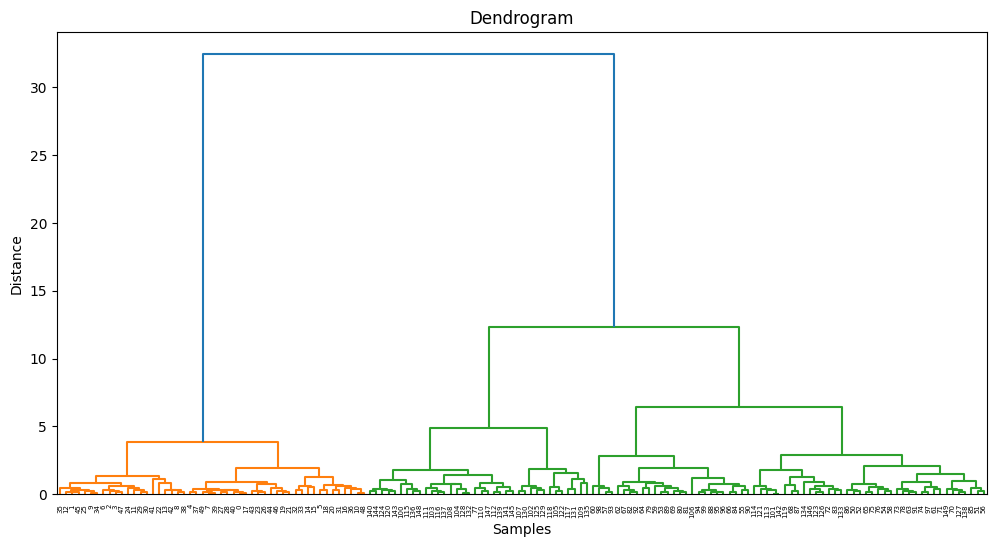

In [10]:
# Create linkage matrix

linked = linkage(
    X,
    method="ward"
)

# Plot dendrogram

plt.figure(figsize=(12,6))

dendrogram(linked)

plt.title("Dendrogram")

plt.xlabel("Samples")

plt.ylabel("Distance")

plt.show()

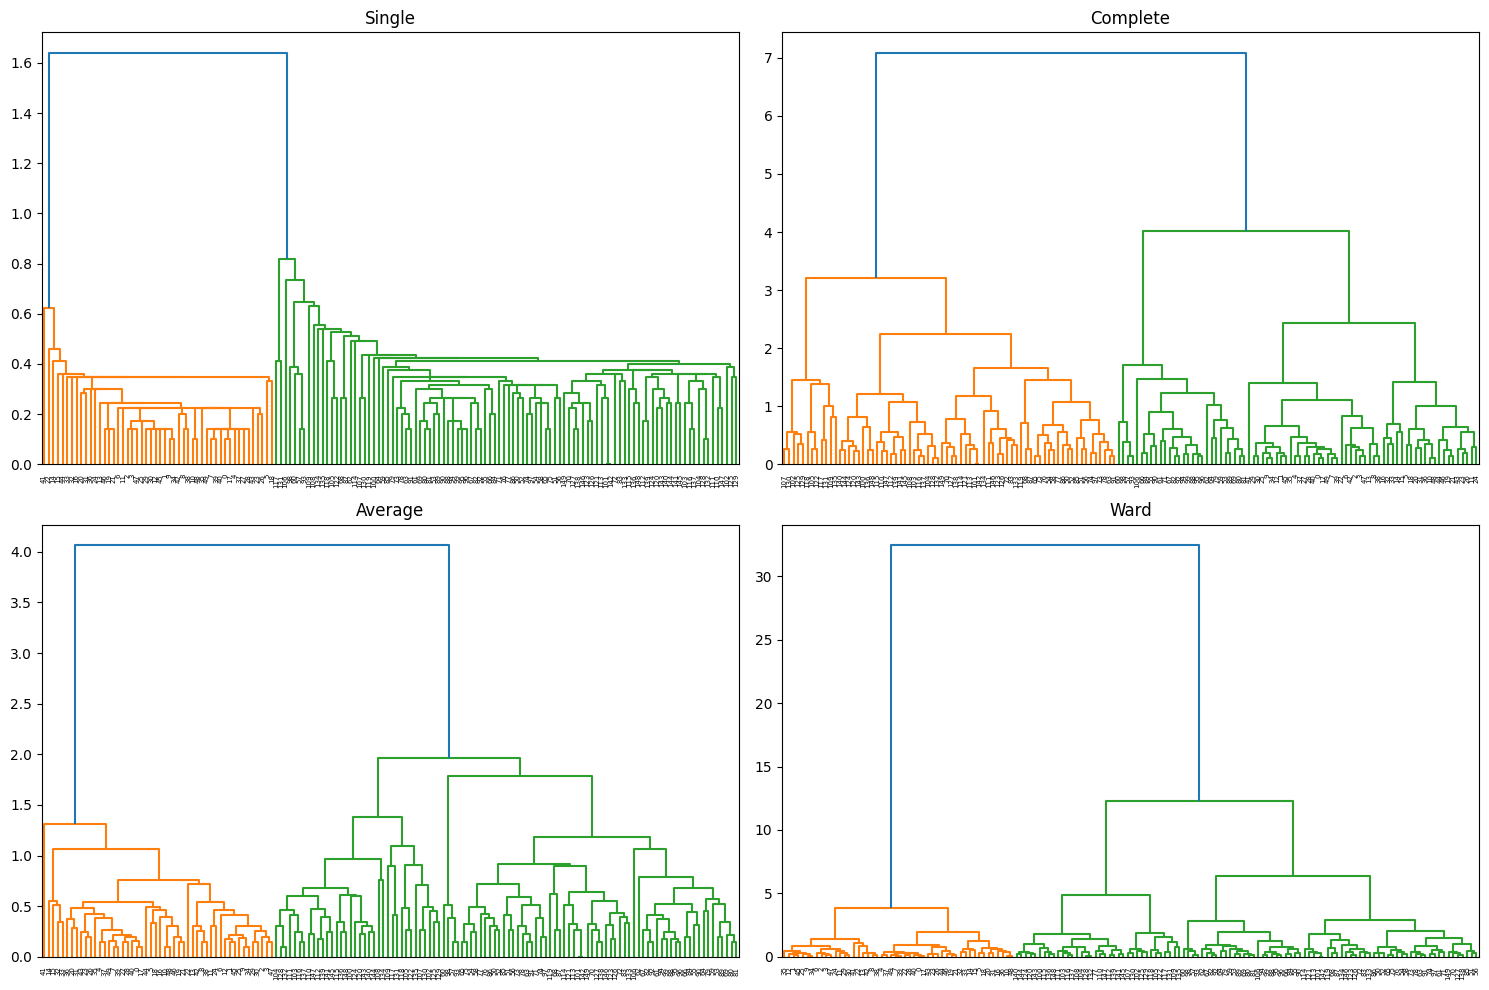

In [11]:
# Compare linkage methods

methods = [
    "single",
    "complete",
    "average",
    "ward"
]

plt.figure(figsize=(15,10))

for i, method in enumerate(methods):

    plt.subplot(2,2,i+1)

    linked = linkage(X, method=method)

    dendrogram(linked)

    plt.title(method.capitalize())

plt.tight_layout()

plt.show()

In [12]:
##### QUESTION 2B ##########
# Import required libraries

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split

from sklearn.ensemble import RandomForestClassifier
from sklearn.ensemble import AdaBoostClassifier
from sklearn.ensemble import GradientBoostingClassifier

from sklearn.metrics import accuracy_score
from sklearn.metrics import confusion_matrix
from sklearn.metrics import ConfusionMatrixDisplay
from sklearn.metrics import classification_report

In [13]:
# Load Breast Cancer dataset

cancer = load_breast_cancer()

cancer_X = cancer.data
cancer_y = cancer.target

# Split the dataset

cancer_X_train, cancer_X_test, cancer_y_train, cancer_y_test = train_test_split(
    cancer_X,
    cancer_y,
    test_size=0.2,
    random_state=42
)

print("Training Samples :", len(cancer_X_train))
print("Testing Samples :", len(cancer_X_test))

Training Samples : 455
Testing Samples : 114


In [14]:
# Create Random Forest model

rf_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

# Train the model

rf_model.fit(cancer_X_train, cancer_y_train)

# Predict

rf_pred = rf_model.predict(cancer_X_test)

# Accuracy

rf_accuracy = accuracy_score(cancer_y_test, rf_pred)

print("Random Forest Accuracy :", rf_accuracy)

Random Forest Accuracy : 0.9649122807017544


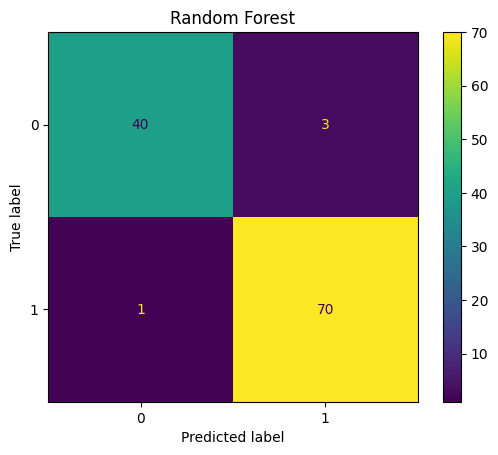

In [15]:
# Display confusion matrix

cm = confusion_matrix(cancer_y_test, rf_pred)

ConfusionMatrixDisplay(cm).plot()

plt.title("Random Forest")

plt.show()

In [16]:
# Print classification report

print(classification_report(cancer_y_test, rf_pred))

              precision    recall  f1-score   support

           0       0.98      0.93      0.95        43
           1       0.96      0.99      0.97        71

    accuracy                           0.96       114
   macro avg       0.97      0.96      0.96       114
weighted avg       0.97      0.96      0.96       114



In [17]:
# Create AdaBoost model

ada_model = AdaBoostClassifier(
    n_estimators=100,
    random_state=42
)

# Train model

ada_model.fit(cancer_X_train, cancer_y_train)

# Predict

ada_pred = ada_model.predict(cancer_X_test)

# Accuracy

ada_accuracy = accuracy_score(cancer_y_test, ada_pred)

print("AdaBoost Accuracy :", ada_accuracy)

AdaBoost Accuracy : 0.9736842105263158


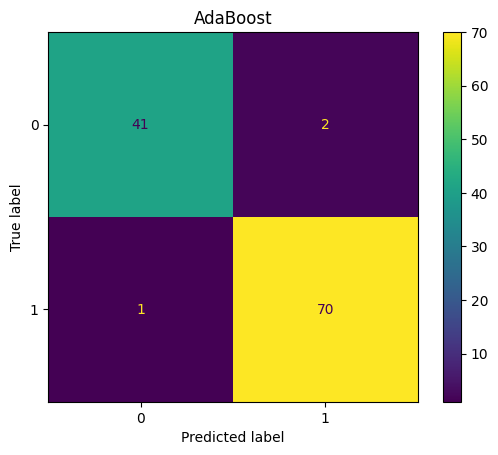

In [18]:
# Display confusion matrix

cm = confusion_matrix(cancer_y_test, ada_pred)

ConfusionMatrixDisplay(cm).plot()

plt.title("AdaBoost")

plt.show()

In [19]:
# Create Gradient Boosting model

gb_model = GradientBoostingClassifier(
    random_state=42
)

# Train model

gb_model.fit(cancer_X_train, cancer_y_train)

# Predict

gb_pred = gb_model.predict(cancer_X_test)

# Accuracy

gb_accuracy = accuracy_score(cancer_y_test, gb_pred)

print("Gradient Boosting Accuracy :", gb_accuracy)

Gradient Boosting Accuracy : 0.956140350877193


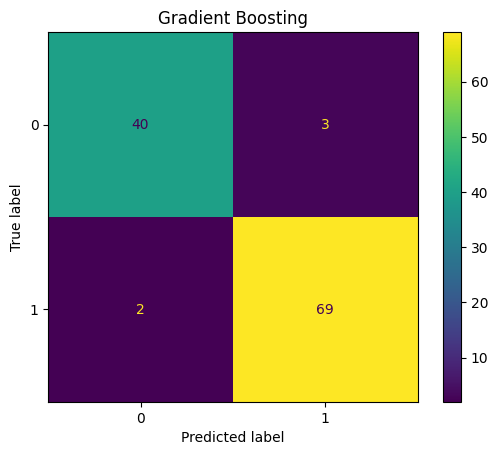

In [20]:
# Display confusion matrix

cm = confusion_matrix(cancer_y_test, gb_pred)

ConfusionMatrixDisplay(cm).plot()

plt.title("Gradient Boosting")

plt.show()

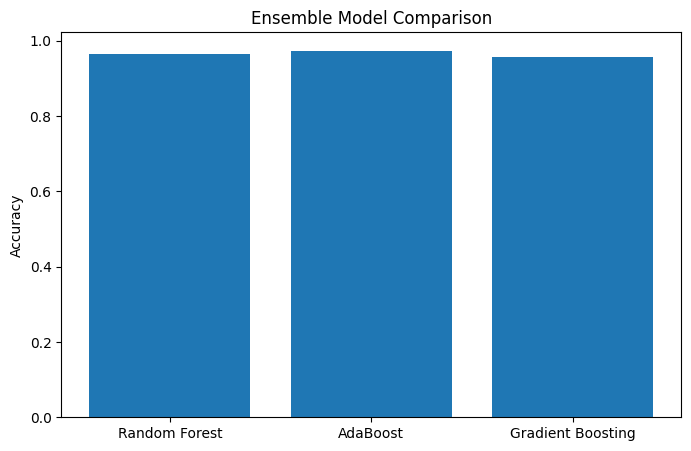

In [21]:
# Compare ensemble models

models = [
    "Random Forest",
    "AdaBoost",
    "Gradient Boosting"
]

accuracy = [
    rf_accuracy,
    ada_accuracy,
    gb_accuracy
]

plt.figure(figsize=(8,5))

plt.bar(models, accuracy)

plt.ylabel("Accuracy")

plt.title("Ensemble Model Comparison")

plt.show()

In [22]:
######################## QUESTION 2C #########################

# Import Gaussian Mixture Model

from sklearn.mixture import GaussianMixture

In [23]:
# Load iris dataset

iris = load_iris()

gmm_X = iris.data

In [24]:
# Create Gaussian Mixture Model

gmm = GaussianMixture(
    n_components=3,
    random_state=42
)

gmm.fit(gmm_X)

gmm_clusters = gmm.predict(gmm_X)

print(gmm_clusters)

[1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1
 1 1 1 1 1 1 1 1 1 1 1 1 1 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 0 2 0 2 0 2
 2 2 2 0 2 2 2 2 2 0 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 0 0 0 0 0 0 0 0 0 0 0
 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0]


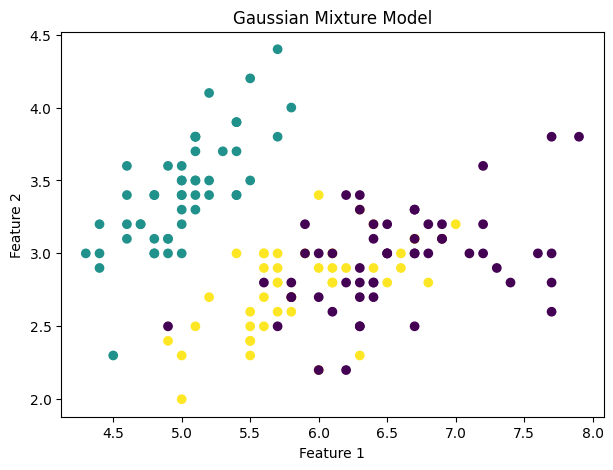

In [25]:
# Plot clusters

plt.figure(figsize=(7,5))

plt.scatter(
    gmm_X[:,0],
    gmm_X[:,1],
    c=gmm_clusters
)

plt.title("Gaussian Mixture Model")

plt.xlabel("Feature 1")

plt.ylabel("Feature 2")

plt.show()

In [26]:
############################ QUESTION 2D ###################################

# Import PCA

from sklearn.decomposition import PCA

In [27]:
# Reduce data to 2 dimensions

pca = PCA(
    n_components=2
)

pca_data = pca.fit_transform(gmm_X)

print("Original Shape :", gmm_X.shape)
print("Reduced Shape :", pca_data.shape)

Original Shape : (150, 4)
Reduced Shape : (150, 2)


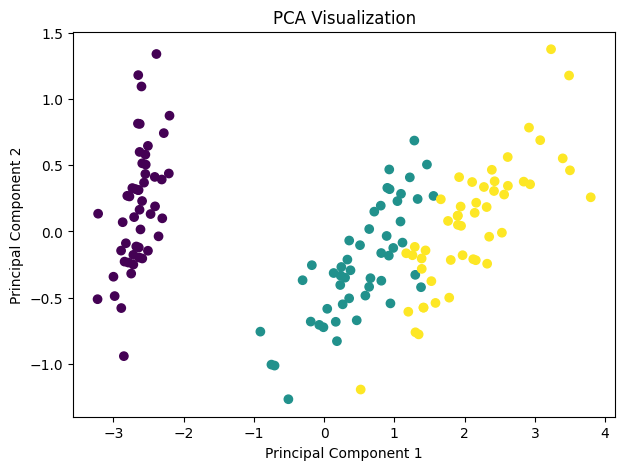

In [28]:
# Plot PCA

plt.figure(figsize=(7,5))

plt.scatter(
    pca_data[:,0],
    pca_data[:,1],
    c=iris.target
)

plt.xlabel("Principal Component 1")

plt.ylabel("Principal Component 2")

plt.title("PCA Visualization")

plt.show()

In [29]:
# Display explained variance

print("Explained Variance Ratio")

print(pca.explained_variance_ratio_)

Explained Variance Ratio
[0.92461872 0.05306648]
